# CNN Image Classification
## CIFAR-10 Classification with Custom CNNs and Transfer Learning

**Author:** Anh Tran

**Environment:** Google Colab with a free T4 GPU

In this project I build two custom convolutional neural networks from scratch, compare 3x3 and 5x5 filters, visualize what the first layer learns, and benchmark them against ResNet50 and EfficientNetB2 using transfer learning. The trained models then classify real photos through a simple prediction interface.

### How to Run in Google Colab

1. **Upload this notebook** at [colab.research.google.com](https://colab.research.google.com)
2. **Turn on the GPU** by choosing `Runtime`, then `Change runtime type`, then `T4 GPU`, then `Save`
3. **Run everything** by clicking `Run all`
4. **Wait about 45 minutes** while the models train

**Approximate time with GPU**
* 3x3 CNN: about 3 minutes
* 5x5 CNN: about 3 minutes
* Filter visualizations: about 30 seconds
* ResNet50: about 24 minutes
* EfficientNetB2: about 15 minutes


## Initial Setup and Imports

In [1]:
# Check if GPU is available
import tensorflow as tf
print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))
print("Num GPUs:", len(tf.config.list_physical_devices('GPU')))
print()
if len(tf.config.list_physical_devices('GPU')) > 0:
    print("GPU detected! Training will be FAST (~20-30 min total)")
else:
    print("No GPU detected. Go to Runtime to Change runtime type to Select GPU")
    print("Without GPU, training will take 2-3 hours.")

: 

In [ ]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50, EfficientNetB2
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.efficientnet import preprocess_input as effnet_preprocess
import time

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

## Load and Prepare CIFAR-10 Dataset

In [ ]:
# Load CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

# Normalize pixel values to [0, 1]
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# CIFAR-10 class names
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

print(f"Training set shape: {x_train.shape}")
print(f"Training labels shape: {y_train.shape}")
print(f"Test set shape: {x_test.shape}")
print(f"Test labels shape: {y_test.shape}")
print(f"Pixel value range: [{x_train.min()}, {x_train.max()}]")

Training set shape: (50000, 32, 32, 3)
Training labels shape: (50000, 1)
Test set shape: (10000, 32, 32, 3)
Test labels shape: (10000, 1)
Pixel value range: [0.0, 1.0]


---
# Section 1: Custom CNN with 3x3 Filters
---

## 1.1 Visualize Random Training Images

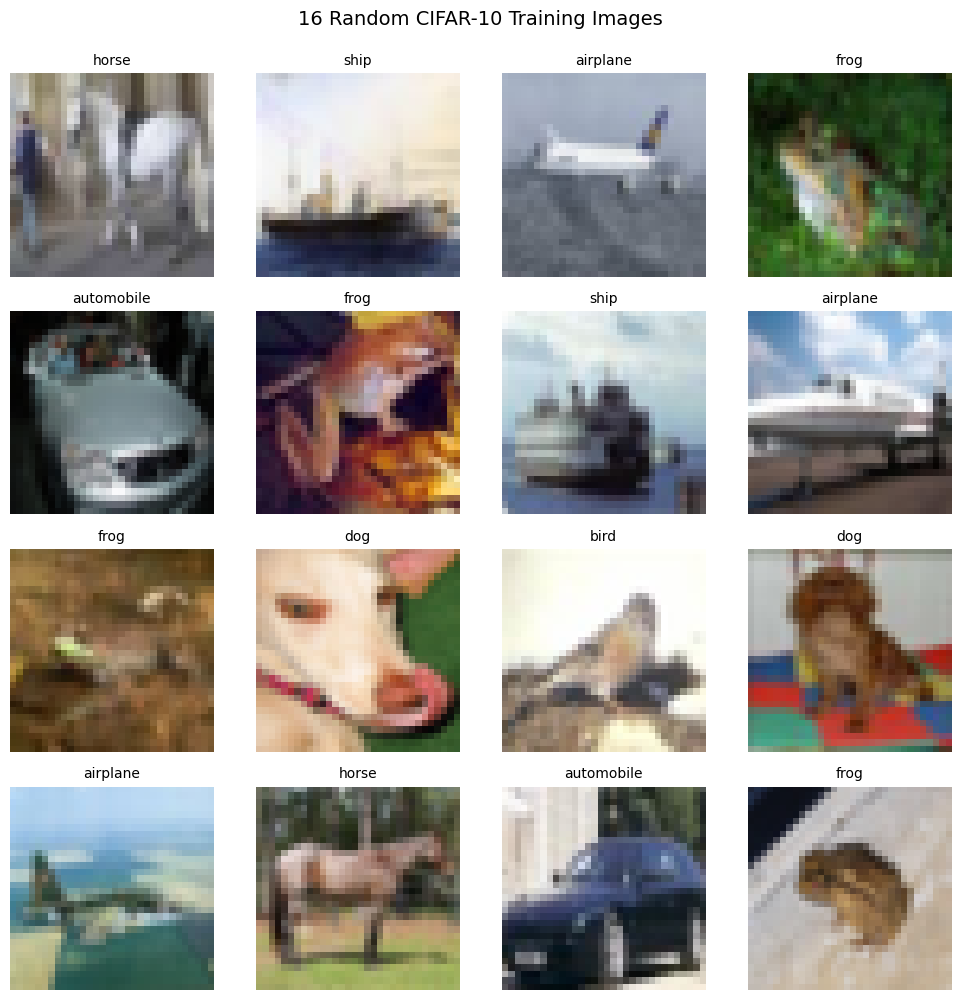

In [ ]:
# Plot 16 random CIFAR-10 training images in a 4x4 grid
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
random_indices = np.random.choice(len(x_train), 16, replace=False)

for i, ax in enumerate(axes.flat):
    idx = random_indices[i]
    ax.imshow(x_train[idx])
    ax.set_title(f"{class_names[y_train[idx][0]]}", fontsize=10)
    ax.axis('off')

plt.suptitle('16 Random CIFAR-10 Training Images', fontsize=14, y=0.995)
plt.tight_layout()
plt.savefig('part1_sample_images.png', dpi=150, bbox_inches='tight')
plt.show()

## 1.2 Build the Custom CNN Architecture

Architecture:
* Input: 32x32x3
* CONV1: 32 filters, 3x3, stride 1, padding "same"
* BatchNorm + ReLU
* CONV2: 32 filters, 3x3, stride 1, padding "same"
* BatchNorm + ReLU
* MaxPool: 2x2, stride 2
* CONV3: 64 filters, 3x3, stride 1, padding "same"
* BatchNorm + ReLU
* MaxPool: 2x2, stride 2
* Flatten
* FC1: 256 neurons + ReLU + Dropout(0.5)
* FC2: 10 neurons (output) + Softmax

In [ ]:
def build_cnn(kernel_size=3, name="custom_cnn"):
    """
    Build custom CNN for CIFAR-10 classification.

    Args:
        kernel_size: Size of convolutional kernels (3 or 5)
        name: Model name for identification

    Returns:
        Compiled Keras model
    """
    k = kernel_size

    model = models.Sequential([
        # Input layer
        layers.Input(shape=(32, 32, 3), name='input'),

        # CONV1: 32 filters
        layers.Conv2D(32, (k, k), padding="same", name='conv1'),
        layers.BatchNormalization(name='bn1'),
        layers.ReLU(name='relu1'),

        # CONV2: 32 filters
        layers.Conv2D(32, (k, k), padding="same", name='conv2'),
        layers.BatchNormalization(name='bn2'),
        layers.ReLU(name='relu2'),

        # MaxPool 2x2
        layers.MaxPooling2D((2, 2), strides=2, name='pool1'),

        # CONV3: 64 filters
        layers.Conv2D(64, (k, k), padding="same", name='conv3'),
        layers.BatchNormalization(name='bn3'),
        layers.ReLU(name='relu3'),

        # MaxPool 2x2
        layers.MaxPooling2D((2, 2), strides=2, name='pool2'),

        # Flatten and Dense layers
        layers.Flatten(name='flatten'),
        layers.Dense(256, name='fc1'),
        layers.ReLU(name='relu4'),
        layers.Dropout(0.5, name='dropout'),
        layers.Dense(10, activation="softmax", name='output'),
    ], name=name)

    return model

In [ ]:
# Build 3x3 CNN
model_3x3 = build_cnn(kernel_size=3, name="cnn_3x3")

# Print model summary
print("CUSTOM CNN WITH 3x3 FILTERS: MODEL SUMMARY")
model_3x3.summary()

# Calculate and display total parameters
total_params = model_3x3.count_params()
print(f"Total learnable parameters: {total_params:,}")

CUSTOM CNN WITH 3x3 FILTERS: MODEL SUMMARY


Model: "cnn_3x3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 32, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (ReLU)                    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 32, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (ReLU)                    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 16, 16, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (ReLU)                    │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (ReLU)                    │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,080,554 (4.12 MB)

 Trainable params: 1,080,298 (4.12 MB)

 Non-trainable params: 256 (1.00 KB)

Total learnable parameters: 1,080,554


## 1.3 Train the 3x3 CNN

In [ ]:
# Compile the model
model_3x3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")
print("Optimizer: Adam (lr=0.001)")
print("Loss: sparse_categorical_crossentropy")
print("Batch size: 64")
print("Epochs: 20")

Model compiled successfully!
Optimizer: Adam (lr=0.001)
Loss: sparse_categorical_crossentropy
Batch size: 64
Epochs: 20


In [ ]:
# Train the model and measure time
print("\nStarting training of 3x3 CNN")

start_time = time.time()

history_3x3 = model_3x3.fit(
    x_train, y_train,
    epochs=20,
    batch_size=64,
    validation_data=(x_test, y_test),
    verbose=1
)

end_time = time.time()
training_time_3x3 = end_time - start_time

print(f"Training completed in {training_time_3x3/60:.2f} minutes")
print(f"Average time per epoch: {training_time_3x3/20:.2f} seconds")



Starting training of 3x3 CNN
Epoch 1/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.4257 - loss: 1.5302 - val_accuracy: 0.5706 - val_loss: 1.2586
Epoch 2/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.4815 - loss: 1.3832 - val_accuracy: 0.5118 - val_loss: 1.3457
Epoch 3/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.5079 - loss: 1.3165 - val_accuracy: 0.5834 - val_loss: 1.1861
Epoch 4/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.5338 - loss: 1.2512 - val_accuracy: 0.6083 - val_loss: 1.0992
Epoch 5/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.5498 - loss: 1.1989 - val_accuracy: 0.6144 - val_loss: 1.1012
Epoch 6/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5633 - loss: 1.1591 - val_accuracy: 0.6617 - val_loss: 1.0093
Epoch 7/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.5754 - loss: 1.1268 - val_accuracy: 0.6730 - val_loss: 0.9429
Epoch 8/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.589

## 1.4 Plot Training Curves and Analyze Results

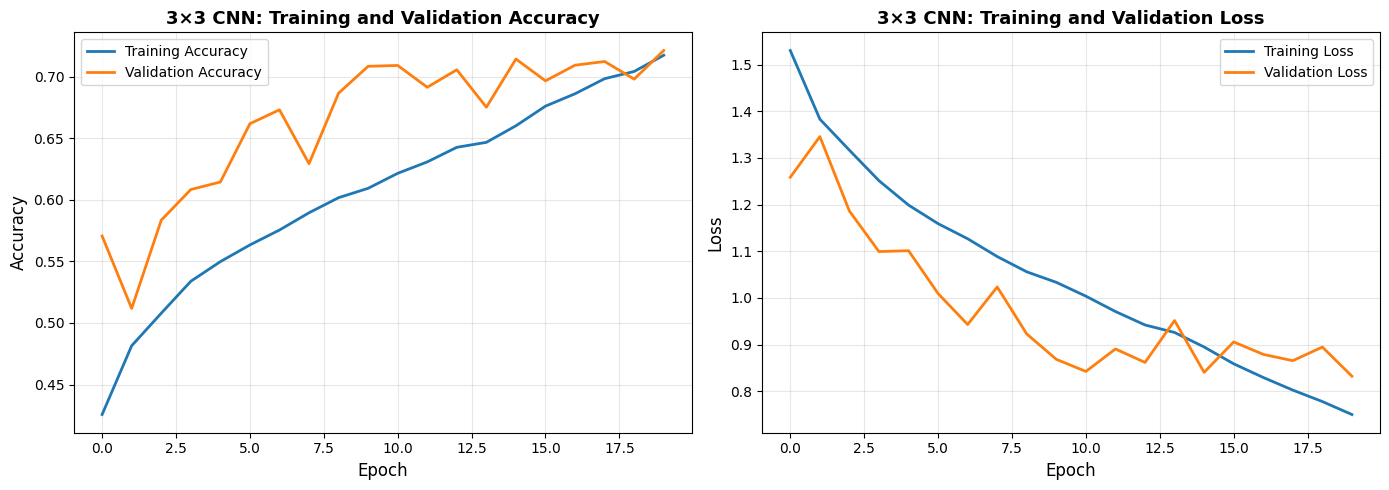

In [ ]:
# Plot training and validation accuracy and loss
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy plot
ax1.plot(history_3x3.history['accuracy'], label='Training Accuracy', linewidth=2)
ax1.plot(history_3x3.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Accuracy', fontsize=12)
ax1.set_title('3x3 CNN: Training and Validation Accuracy', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# Loss plot
ax2.plot(history_3x3.history['loss'], label='Training Loss', linewidth=2)
ax2.plot(history_3x3.history['val_loss'], label='Validation Loss', linewidth=2)
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Loss', fontsize=12)
ax2.set_title('3x3 CNN: Training and Validation Loss', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('part1_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Calculate final metrics
final_train_acc_3x3 = history_3x3.history['accuracy'][-1]
final_test_acc_3x3 = history_3x3.history['val_accuracy'][-1]
accuracy_gap_3x3 = final_train_acc_3x3 - final_test_acc_3x3

print("3x3 CNN FINAL RESULTS")
print(f"Final Training Accuracy:   {final_train_acc_3x3*100:.2f}%")
print(f"Final Test Accuracy:       {final_test_acc_3x3*100:.2f}%")
print(f"Accuracy Gap:              {accuracy_gap_3x3*100:.2f}%")

# Overfitting analysis
print("\nOverfitting Analysis:")
if accuracy_gap_3x3 > 0.05:  # More than 5% gap
    print(f"The model IS overfitting.")
    print(f"The training accuracy ({final_train_acc_3x3*100:.2f}%) is significantly higher")
    print(f"than the test accuracy ({final_test_acc_3x3*100:.2f}%), with a gap of {accuracy_gap_3x3*100:.2f}%.")
    print(f"This indicates the model has memorized training patterns that don't")
    print(f"generalize well to unseen test data. The dropout layer helps, but more")
    print(f"regularization (data augmentation, higher dropout, L2 regularization) could improve this.")
else:
    print(f"The model is NOT significantly overfitting.")
    print(f"The gap between training ({final_train_acc_3x3*100:.2f}%) and test accuracy")
    print(f"({final_test_acc_3x3*100:.2f}%) is only {accuracy_gap_3x3*100:.2f}%, which is acceptable.")
    print(f"The dropout layer is effectively preventing overfitting.")


3x3 CNN FINAL RESULTS
Final Training Accuracy:   71.73%
Final Test Accuracy:       72.11%
Accuracy Gap:              -0.38%

Overfitting Analysis:
The model is NOT significantly overfitting.
The gap between training (71.73%) and test accuracy
(72.11%) is only -0.38%, which is acceptable.
The dropout layer is effectively preventing overfitting.


## 1.5 Save the Model

In [ ]:
# Save the trained model
model_3x3.save("cnn_3x3.keras")
print("Model saved as 'cnn_3x3.keras'")
print("Download this file before closing Colab session!")

Model saved as 'cnn_3x3.keras'
Download this file before closing Colab session!


---
# Section 2: Filter Size Experiment, 5x5 vs 3x3
---

## 2.1 Build and Summarize the 5x5 CNN

In [ ]:
# Build 5x5 CNN using the same function
model_5x5 = build_cnn(kernel_size=5, name="cnn_5x5")

# Print model summary
print("Custom CNN With 5x5 Filters: Model Summary")
model_5x5.summary()

# Calculate and display total parameters
total_params_5x5 = model_5x5.count_params()
print(f"Total learnable parameters: {total_params_5x5:,}")
print(f"Difference from 3x3 network: {total_params_5x5 - total_params:+,} parameters")

Custom CNN With 5x5 Filters: Model Summary


Model: "cnn_5x5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 32, 32, 32)     │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 32, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (ReLU)                    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 32)     │        25,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 32, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (ReLU)                    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 16, 16, 64)     │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 16, 16, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (ReLU)                    │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (ReLU)                    │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,131,242 (4.32 MB)

 Trainable params: 1,130,986 (4.31 MB)

 Non-trainable params: 256 (1.00 KB)

Total learnable parameters: 1,131,242
Difference from 3x3 network: +50,688 parameters


## 2.2 Train the 5x5 CNN

In [ ]:
# Compile the 5x5 model
model_5x5.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("5x5 Model compiled successfully!")
print("Using identical training configuration as 3x3 model.")

5x5 Model compiled successfully!
Using identical training configuration as 3x3 model.


In [ ]:
# Train the 5x5 model and measure time
print("\nStarting training of 5x5 CNN")

start_time = time.time()

history_5x5 = model_5x5.fit(
    x_train, y_train,
    epochs=20,
    batch_size=64,
    validation_data=(x_test, y_test),
    verbose=1
)

end_time = time.time()
training_time_5x5 = end_time - start_time

print(f"Training completed in {training_time_5x5/60:.2f} minutes")
print(f"Average time per epoch: {training_time_5x5/20:.2f} seconds")


Starting training of 5x5 CNN
Epoch 1/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 25s 24ms/step - accuracy: 0.3183 - loss: 1.8436 - val_accuracy: 0.4252 - val_loss: 1.5902
Epoch 2/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 26s 10ms/step - accuracy: 0.4301 - loss: 1.5111 - val_accuracy: 0.4996 - val_loss: 1.3617
Epoch 3/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.4848 - loss: 1.3676 - val_accuracy: 0.5842 - val_loss: 1.1783
Epoch 4/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.5127 - loss: 1.2936 - val_accuracy: 0.6182 - val_loss: 1.0949
Epoch 5/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.5408 - loss: 1.2249 - val_accuracy: 0.6345 - val_loss: 1.0638
Epoch 6/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.5649 - loss: 1.1639 - val_accuracy: 0.6851 - val_loss: 0.9166
Epoch 7/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.5868 - loss: 1.1006 - val_accuracy: 0.6610 - val_loss: 0.9760
Epoch 8/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 

## 2.3 Comparison Table

In [ ]:
# Calculate CONV1 parameters for both networks
# CONV1 params = (kernel_height x kernel_width x input_channels + 1_bias) x num_filters
# For 3x3: (3 x 3 x 3 + 1) x 32 = 28 x 32 = 896
# For 5x5: (5 x 5 x 3 + 1) x 32 = 76 x 32 = 2,432

conv1_params_3x3 = (3 * 3 * 3 + 1) * 32
conv1_params_5x5 = (5 * 5 * 3 + 1) * 32

# Get final accuracies
final_train_acc_5x5 = history_5x5.history['accuracy'][-1]
final_test_acc_5x5 = history_5x5.history['val_accuracy'][-1]

# Create comparison table
print("Comparison Table: 3x3 vs 5x5 Networks")
print(f"{'Quantity':<30} {'3x3 network':<20} {'5x5 network':<20}")
print(f"{'CONV1 parameters':<30} {conv1_params_3x3:<20,} {conv1_params_5x5:<20,}")
print(f"{'Total parameters':<30} {total_params:<20,} {total_params_5x5:<20,}")
print(f"{'Final training accuracy':<30} {final_train_acc_3x3*100:<20.2f}% {final_train_acc_5x5*100:<20.2f}%")
print(f"{'Final test accuracy':<30} {final_test_acc_3x3*100:<20.2f}% {final_test_acc_5x5*100:<20.2f}%")
print(f"{'Wall-clock training time':<30} {training_time_3x3:<20.1f}s {training_time_5x5:<20.1f}s")


Comparison Table: 3x3 vs 5x5 Networks
Quantity                       3x3 network          5x5 network         
CONV1 parameters               896                  2,432               
Total parameters               1,080,554            1,131,242           
Final training accuracy        71.73               % 74.92               %
Final test accuracy            72.11               % 68.68               %
Wall-clock training time       152.4               s 202.9               s


## 2.4 Overlay Accuracy Curves

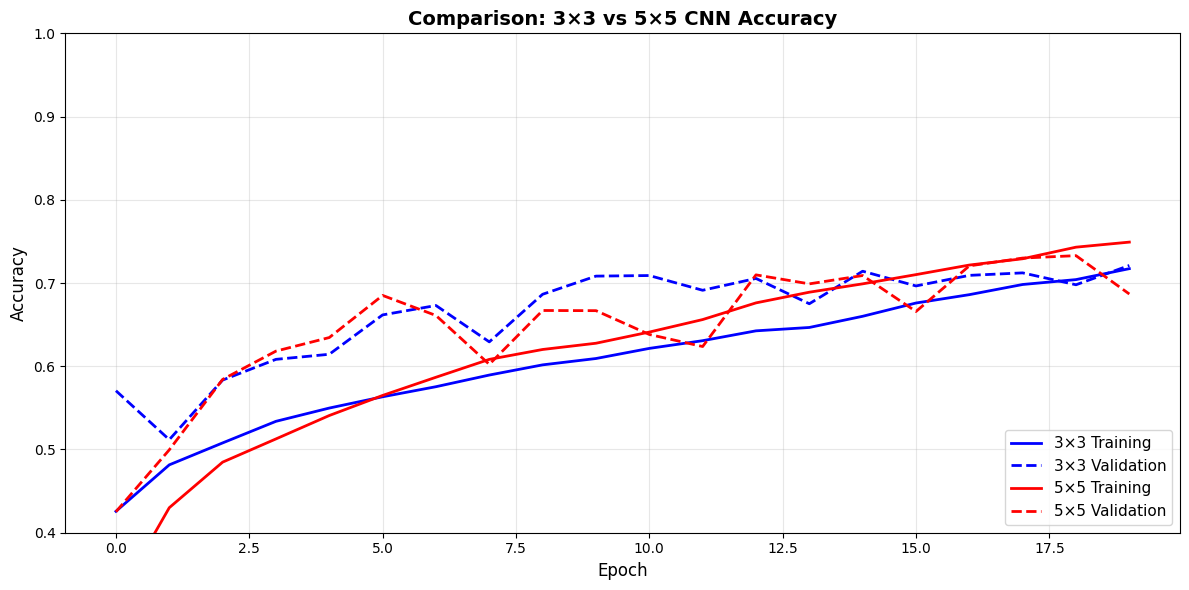

In [ ]:
# Plot training and validation accuracy curves for both networks on same figure
plt.figure(figsize=(12, 6))

# 3x3 curves
plt.plot(history_3x3.history['accuracy'], label='3x3 Training',
         linewidth=2, linestyle='-', color='blue')
plt.plot(history_3x3.history['val_accuracy'], label='3x3 Validation',
         linewidth=2, linestyle='--', color='blue')

# 5x5 curves
plt.plot(history_5x5.history['accuracy'], label='5x5 Training',
         linewidth=2, linestyle='-', color='red')
plt.plot(history_5x5.history['val_accuracy'], label='5x5 Validation',
         linewidth=2, linestyle='--', color='red')

plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.title('Comparison: 3x3 vs 5x5 CNN Accuracy', fontsize=14, fontweight='bold')
plt.legend(fontsize=11, loc='lower right')
plt.grid(True, alpha=0.3)
plt.ylim([0.4, 1.0])

plt.tight_layout()
plt.savefig('part2_comparison_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 2.5 Save the 5x5 Model

In [ ]:
# Save the 5x5 model
model_5x5.save("cnn_5x5.keras")
print("Model saved as 'cnn_5x5.keras'")
print("Download this file before closing Colab session.")

Model saved as 'cnn_5x5.keras'
Download this file before closing Colab session.


---
# Section 3: Visualizing Learned Filters
---

## 3.1 Visualize 3x3 CONV1 Filters

In [ ]:
def visualize_conv1_filters(model, kernel_size, title, save_name):
    """
    Extract and visualize the first convolutional layer filters.

    Args:
        model: Trained Keras model
        kernel_size: Size of kernels (3 or 5)
        title: Plot title
        save_name: Filename to save the figure
    """
    # Get CONV1 weights (first Conv2D layer after Input)
    # Layer index 0 is the first Conv2D layer in our Sequential model
    W = model.layers[0].get_weights()[0]  # Shape: (k, k, 3, 32)
    n_filters = W.shape[-1]  # Should be 32

    print(f"CONV1 weight tensor shape: {W.shape}")
    print(f"Number of filters: {n_filters}")

    # Create 4x8 grid for 32 filters
    fig, axes = plt.subplots(4, 8, figsize=(12, 6))

    for i, ax in enumerate(axes.flat):
        # Get the i-th filter (k x k x 3)
        f = W[:, :, :, i]

        # Normalize each filter to [0, 1] for display
        f_min = f.min()
        f_max = f.max()
        if f_max - f_min > 1e-8:  # Avoid division by zero
            f_normalized = (f - f_min) / (f_max - f_min)
        else:
            f_normalized = f - f_min

        # Display as RGB image
        ax.imshow(f_normalized)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(f'F{i}', fontsize=8)

    plt.suptitle(title, fontsize=14, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.savefig(save_name, dpi=150, bbox_inches='tight')
    plt.show()

    return W

Extracting and visualizing 3x3 CONV1 filters...
CONV1 weight tensor shape: (3, 3, 3, 32)
Number of filters: 32


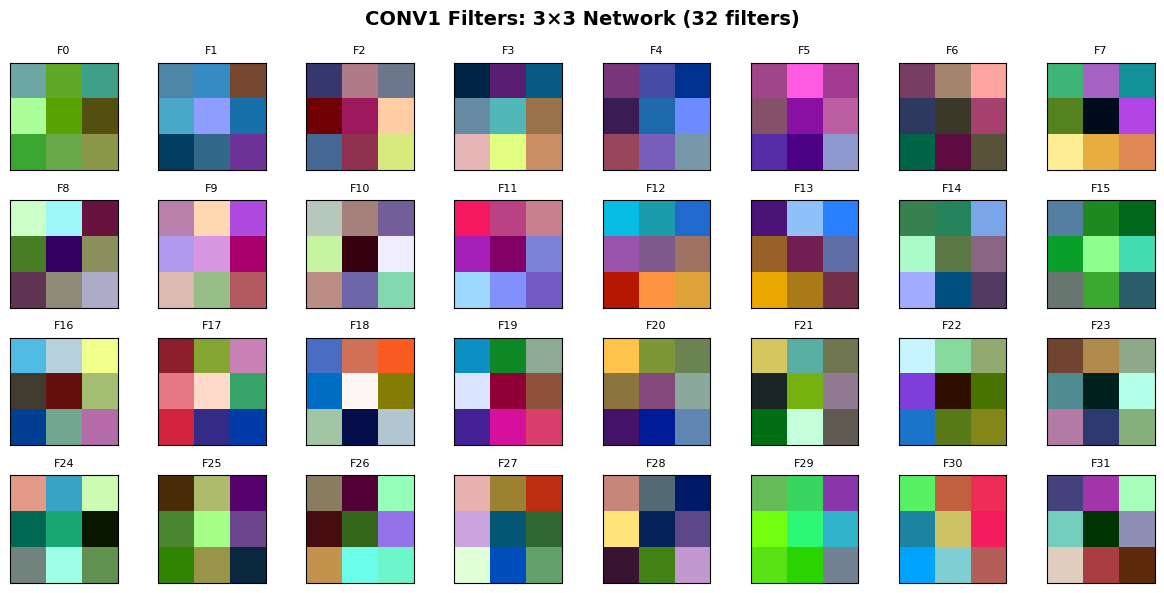

In [ ]:
# Visualize 3x3 filters
print("Extracting and visualizing 3x3 CONV1 filters...")
W_3x3 = visualize_conv1_filters(
    model_3x3,
    kernel_size=3,
    title='CONV1 Filters: 3x3 Network (32 filters)',
    save_name='filters_3x3.png'
)

## 3.2 Visualize 5x5 CONV1 Filters

Extracting and visualizing 5x5 CONV1 filters
CONV1 weight tensor shape: (5, 5, 3, 32)
Number of filters: 32


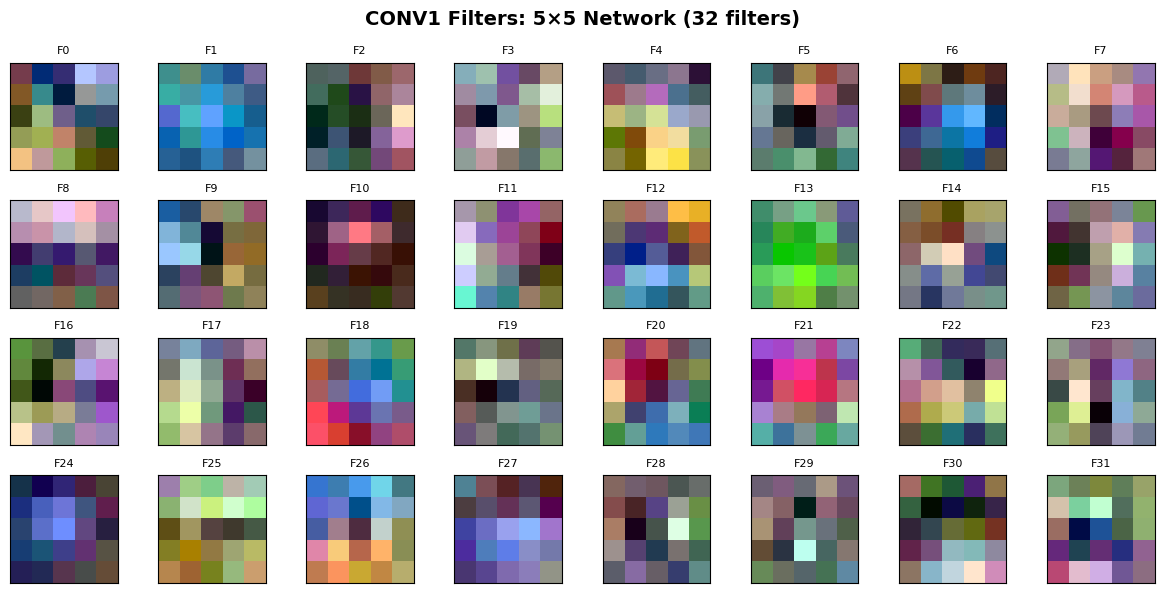

In [ ]:
# Visualize 5x5 filters
print("Extracting and visualizing 5x5 CONV1 filters")
W_5x5 = visualize_conv1_filters(
    model_5x5,
    kernel_size=5,
    title='CONV1 Filters: 5x5 Network (32 filters)',
    save_name='filters_5x5.png'
)

---
# Section 4: Transfer Learning with ResNet50 and EfficientNetB2
---

## 4.1 Build the ResNet50 Transfer Learning Model

In [ ]:
def build_transfer_learning_model(backbone_name='resnet50'):
    """
    Build transfer learning model with frozen ImageNet backbone.

    Args:
        backbone_name: 'resnet50' or 'efficientnetb2'

    Returns:
        Compiled Keras model
    """
    # Configure based on backbone
    if backbone_name == 'resnet50':
        input_size = 224
        backbone_class = ResNet50
        preprocess_fn = resnet_preprocess
    elif backbone_name == 'efficientnetb2':
        input_size = 260
        backbone_class = EfficientNetB2
        preprocess_fn = effnet_preprocess
    else:
        raise ValueError("backbone_name must be 'resnet50' or 'efficientnetb2'")

    # Build model using Functional API
    inputs = layers.Input(shape=(32, 32, 3), name='input')

    # Resize to expected input size
    x = layers.Resizing(input_size, input_size, name='resize')(inputs)

    # Apply backbone-specific preprocessing
    x = preprocess_fn(x)

    # Load frozen backbone
    backbone = backbone_class(weights='imagenet', include_top=False)
    backbone.trainable = False  # Freeze all backbone weights

    # Pass through backbone
    x = backbone(x, training=False)  # Important for frozen BatchNorm layers

    # Classifier head
    x = layers.GlobalAveragePooling2D(name='global_pool')(x)
    x = layers.BatchNormalization(name='bn')(x)
    x = layers.Dense(128, activation='relu', name='fc1')(x)
    x = layers.Dropout(0.3, name='dropout')(x)
    outputs = layers.Dense(10, activation='softmax', name='output')(x)

    # Create model
    model = models.Model(inputs, outputs, name=f'{backbone_name}_transfer')

    return model, backbone

In [ ]:
# Build ResNet50 transfer learning model
print("Building ResNet50 Transfer Learning Model...")
model_resnet50, backbone_resnet = build_transfer_learning_model('resnet50')

# Print summary
model_resnet50.summary()

# Count trainable vs non-trainable parameters
trainable_params_resnet = sum([tf.size(w).numpy() for w in model_resnet50.trainable_weights])
non_trainable_params_resnet = sum([tf.size(w).numpy() for w in model_resnet50.non_trainable_weights])
total_params_resnet = trainable_params_resnet + non_trainable_params_resnet

print("ResNet50 Transfer Learning: Parameter Count")
print(f"Total parameters:          {total_params_resnet:>15,}")
print(f"Trainable parameters:      {trainable_params_resnet:>15,}")
print(f"Non-trainable parameters:  {non_trainable_params_resnet:>15,}")


Building ResNet50 Transfer Learning Model...


Model: "resnet50_transfer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, 32, 32, 3) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resize (Resizing)   │ (None, 224, 224,  │          0 │ input[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_3          │ (None, 224, 224)  │          0 │ resize[0][0]      │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_4          │ (None, 224, 224)  │          0 │ resize[0][0]      │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_5          │ (None, 224, 224)  │          0 │ resize[0][0]      │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack_1 (Stack)     │ (None, 224, 224,  │          0 │ get_item_3[0][0], │
│                     │ 3)                │            │ get_item_4[0][0], │
│                     │                   │            │ get_item_5[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 224, 224,  │          0 │ stack_1[0][0]     │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add_1[0][0]       │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_pool         │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn                  │ (None, 2048)      │      8,192 │ global_pool[0][0] │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fc1 (Dense)         │ (None, 128)       │    262,272 │ bn[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ fc1[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, 10)        │      1,290 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,859,466 (91.02 MB)

 Trainable params: 267,658 (1.02 MB)

 Non-trainable params: 23,591,808 (90.00 MB)

ResNet50 Transfer Learning: Parameter Count
Total parameters:               23,859,466
Trainable parameters:              267,658
Non-trainable parameters:       23,591,808


In [ ]:
# Compile ResNet50 model
model_resnet50.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("ResNet50 model compiled successfully.")

ResNet50 model compiled successfully.


In [ ]:
# Train ResNet50 model
print("\nStarting training of ResNet50 transfer learning model")
print("This will take longer time.")

start_time = time.time()

history_resnet50 = model_resnet50.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_test, y_test),
    verbose=1
)

end_time = time.time()
training_time_resnet50 = end_time - start_time

print(f"ResNet50 training completed in {training_time_resnet50/60:.2f} minutes")
print(f"Average time per epoch: {training_time_resnet50/10:.2f} seconds")



Starting training of ResNet50 transfer learning model
This will take longer time.
Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 216s 243ms/step - accuracy: 0.4366 - loss: 1.5862 - val_accuracy: 0.5122 - val_loss: 1.3937
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 228s 219ms/step - accuracy: 0.5027 - loss: 1.4042 - val_accuracy: 0.5360 - val_loss: 1.3056
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 170s 217ms/step - accuracy: 0.5252 - loss: 1.3422 - val_accuracy: 0.5517 - val_loss: 1.2651
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 169s 217ms/step - accuracy: 0.5401 - loss: 1.3029 - val_accuracy: 0.5659 - val_loss: 1.2344
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 171s 219ms/step - accuracy: 0.5503 - loss: 1.2713 - val_accuracy: 0.5718 - val_loss: 1.2173
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 170s 217ms/step - accuracy: 0.5632 - loss: 1.2426 - val_accuracy: 0.5792 - val_loss: 1.1997
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 169s 216ms/step - accuracy: 0.5698 - loss: 1.2227 - val_accuracy: 0.5800 - val_loss: 

## 4.2 Build the EfficientNetB2 Transfer Learning Model

In [ ]:
# Build EfficientNetB2 transfer learning model
print("Building EfficientNetB2 Transfer Learning Model")

model_effnetb2, backbone_effnet = build_transfer_learning_model('efficientnetb2')

# Print summary
model_effnetb2.summary()

# Count trainable vs non-trainable parameters
trainable_params_effnet = sum([tf.size(w).numpy() for w in model_effnetb2.trainable_weights])
non_trainable_params_effnet = sum([tf.size(w).numpy() for w in model_effnetb2.non_trainable_weights])
total_params_effnet = trainable_params_effnet + non_trainable_params_effnet

print("EfficientNetB2 Transfer Learning: Parameter Count")
print(f"Total parameters:          {total_params_effnet:>15,}")
print(f"Trainable parameters:      {trainable_params_effnet:>15,}")
print(f"Non-trainable parameters:  {non_trainable_params_effnet:>15,}")


Building EfficientNetB2 Transfer Learning Model
31790344/31790344 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "efficientnetb2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resize (Resizing)               │ (None, 260, 260, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb2 (Functional)     │ (None, 8, 8, 1408)     │     7,768,569 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_pool                     │ (None, 1408)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn (BatchNormalization)         │ (None, 1408)           │         5,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 128)            │       180,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,955,843 (30.35 MB)

 Trainable params: 184,458 (720.54 KB)

 Non-trainable params: 7,771,385 (29.65 MB)

EfficientNetB2 Transfer Learning: Parameter Count
Total parameters:                7,955,843
Trainable parameters:              184,458
Non-trainable parameters:        7,771,385


In [ ]:
# Compile EfficientNetB2 model
model_effnetb2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("EfficientNetB2 model compiled successfully.")

EfficientNetB2 model compiled successfully.


In [ ]:
# Train EfficientNetB2 model
print("\nStarting training of EfficientNetB2 transfer learning model...")
print("This may take longer due to the large backbone size.")

start_time = time.time()

history_effnetb2 = model_effnetb2.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_test, y_test),
    verbose=1
)

end_time = time.time()
training_time_effnetb2 = end_time - start_time

print(f"EfficientNetB2 training completed in {training_time_effnetb2/60:.2f} minutes")
print(f"Average time per epoch: {training_time_effnetb2/10:.2f} seconds")



Starting training of EfficientNetB2 transfer learning model...
This may take longer due to the large backbone size.
Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 213s 214ms/step - accuracy: 0.0994 - loss: 2.3819 - val_accuracy: 0.1000 - val_loss: 2.3027
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 120s 153ms/step - accuracy: 0.0981 - loss: 2.3044 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 120s 153ms/step - accuracy: 0.0999 - loss: 2.3033 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 120s 153ms/step - accuracy: 0.0998 - loss: 2.3031 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 119s 152ms/step - accuracy: 0.0979 - loss: 2.3035 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 120s 154ms/step - accuracy: 0.0974 - loss: 2.3030 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 120s 154ms/step - accuracy: 0.0983 - loss: 2.3028 -

## 4.3 Plot Training Curves

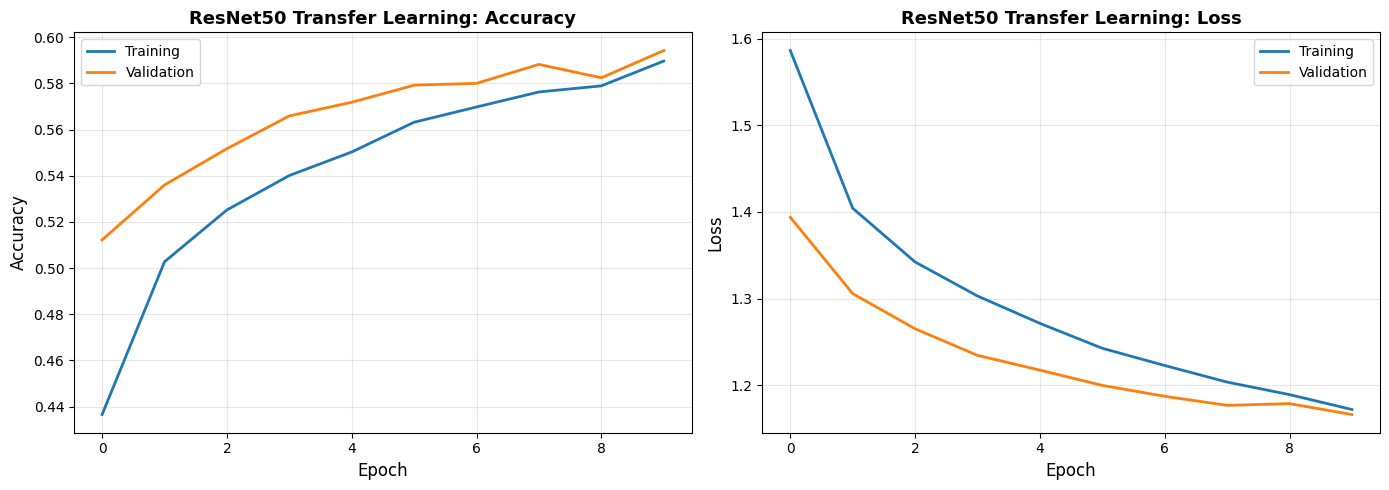

In [ ]:
# Plot ResNet50 curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
ax1.plot(history_resnet50.history['accuracy'], label='Training', linewidth=2)
ax1.plot(history_resnet50.history['val_accuracy'], label='Validation', linewidth=2)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Accuracy', fontsize=12)
ax1.set_title('ResNet50 Transfer Learning: Accuracy', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# Loss
ax2.plot(history_resnet50.history['loss'], label='Training', linewidth=2)
ax2.plot(history_resnet50.history['val_loss'], label='Validation', linewidth=2)
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Loss', fontsize=12)
ax2.set_title('ResNet50 Transfer Learning: Loss', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('part4_resnet50_curves.png', dpi=150, bbox_inches='tight')
plt.show()

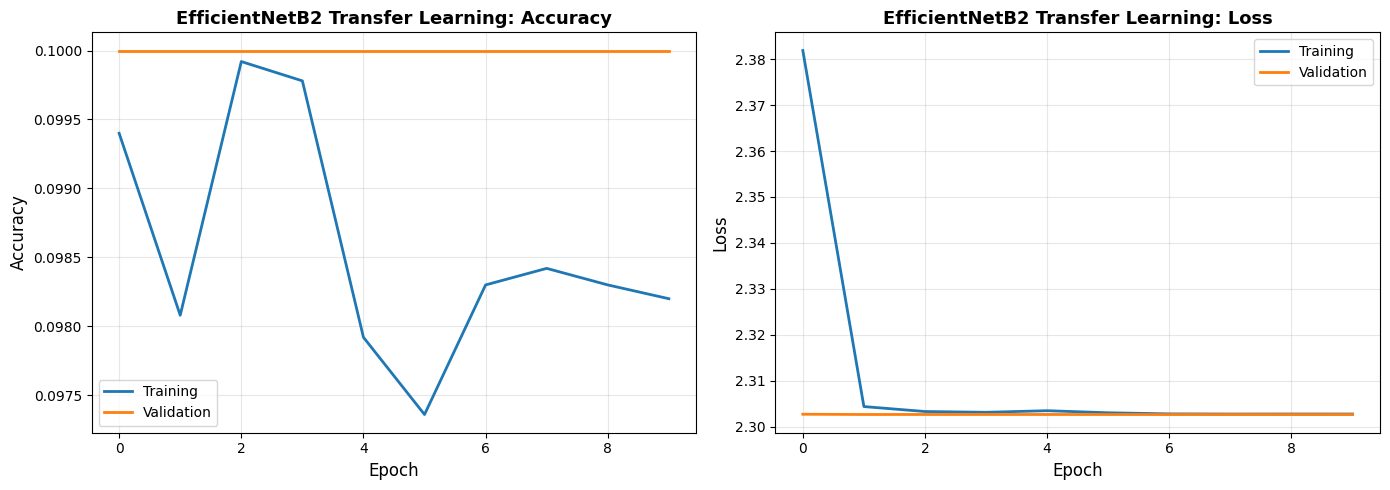

In [ ]:
# Plot EfficientNetB2 curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
ax1.plot(history_effnetb2.history['accuracy'], label='Training', linewidth=2)
ax1.plot(history_effnetb2.history['val_accuracy'], label='Validation', linewidth=2)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Accuracy', fontsize=12)
ax1.set_title('EfficientNetB2 Transfer Learning: Accuracy', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# Loss
ax2.plot(history_effnetb2.history['loss'], label='Training', linewidth=2)
ax2.plot(history_effnetb2.history['val_loss'], label='Validation', linewidth=2)
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Loss', fontsize=12)
ax2.set_title('EfficientNetB2 Transfer Learning: Loss', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('part4_effnetb2_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 4.4 Final Test Accuracies and Model Comparison

In [ ]:
# Get final test accuracies
final_test_acc_resnet50 = history_resnet50.history['val_accuracy'][-1]
final_test_acc_effnetb2 = history_effnetb2.history['val_accuracy'][-1]

print("Final Test Accuracy")
print(f"ResNet50 (frozen):      {final_test_acc_resnet50*100:.2f}%")
print(f"EfficientNetB2 (frozen): {final_test_acc_effnetb2*100:.2f}%")


Final Test Accuracy
ResNet50 (frozen):      59.42%
EfficientNetB2 (frozen): 10.00%


In [ ]:
# Consolidated comparison table
print("Model Comparison: All Models")
print(f"{'Model':<30} {'Total params':<20} {'Trainable params':<20} {'Test accuracy':<15} {'Time/epoch'}")

print(f"{'Custom CNN (3x3)':<30} {total_params:<20,} {total_params:<20,} "
      f"{final_test_acc_3x3*100:<15.2f}% {training_time_3x3/20:<.1f}s")

print(f"{'Custom CNN (5x5)':<30} {total_params_5x5:<20,} {total_params_5x5:<20,} "
      f"{final_test_acc_5x5*100:<15.2f}% {training_time_5x5/20:<.1f}s")

print(f"{'ResNet50 (frozen)':<30} {total_params_resnet:<20,} {trainable_params_resnet:<20,} "
      f"{final_test_acc_resnet50*100:<15.2f}% {training_time_resnet50/10:<.1f}s")

print(f"{'EfficientNetB2 (frozen)':<30} {total_params_effnet:<20,} {trainable_params_effnet:<20,} "
      f"{final_test_acc_effnetb2*100:<15.2f}% {training_time_effnetb2/10:<.1f}s")

Model Comparison: All Models
Model                          Total params         Trainable params     Test accuracy   Time/epoch
Custom CNN (3x3)               1,080,554            1,080,554            72.11          % 7.6s
Custom CNN (5x5)               1,131,242            1,131,242            68.68          % 10.1s
ResNet50 (frozen)              23,859,466           267,658              59.42          % 180.3s
EfficientNetB2 (frozen)        7,955,843            184,458              10.00          % 129.1s


## 4.5 Analysis

In [ ]:
# Determine winner
accuracies = {
    'Custom CNN (3x3)': final_test_acc_3x3,
    'Custom CNN (5x5)': final_test_acc_5x5,
    'ResNet50 (frozen)': final_test_acc_resnet50,
    'EfficientNetB2 (frozen)': final_test_acc_effnetb2
}
winner = max(accuracies, key=accuracies.get)
winner_acc = accuracies[winner]

print("ANALYSIS")
print()
print("Which model wins on accuracy?")
print()
print(f"Answer: {winner} achieves the highest test accuracy at {winner_acc*100:.2f}%.")

print(f"See the README for the full discussion.")


ANALYSIS

Which model wins on accuracy?

Answer: Custom CNN (3x3) achieves the highest test accuracy at 72.11%.
See the README for the full discussion.


## 4.6 Save the Transfer Learning Models

In [ ]:
# Save both transfer learning models
model_resnet50.save("resnet50_tl.keras")
print("ResNet50 model saved as 'resnet50_tl.keras'")

model_effnetb2.save("effnetb2_tl.keras")
print("EfficientNetB2 model saved as 'effnetb2_tl.keras'")

print("Reminder: Download all 4 model files before closing this Colab session.")
print("Click the folder icon on the left sidebar, right-click each file → Download")
print("Files to download:")
print("cnn_3x3.keras")
print("cnn_5x5.keras")
print("resnet50_tl.keras")
print("effnetb2_tl.keras")

ResNet50 model saved as 'resnet50_tl.keras'
EfficientNetB2 model saved as 'effnetb2_tl.keras'
Reminder: Download all 4 model files before closing this Colab session.
Click the folder icon on the left sidebar, right-click each file → Download
Files to download:
cnn_3x3.keras
cnn_5x5.keras
resnet50_tl.keras
effnetb2_tl.keras


---
# Section 5: Classifying Real Photos
---
## 5.1 Import Libraries and Setup

In [ ]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
from PIL import Image
from datetime import datetime
import os
import glob

# CIFAR-10 class names
CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

print("Libraries imported successfully!")

## 5.2 Define Helper Functions

In [ ]:
def preprocess_image(image, target_size, preprocess_type='standard'):
    """Preprocess image for model prediction."""
    image = image.resize((target_size, target_size), Image.LANCZOS)
    img_array = np.array(image)

    # Ensure RGB
    if len(img_array.shape) == 2:
        img_array = np.stack([img_array] * 3, axis=-1)
    elif img_array.shape[-1] == 4:
        img_array = img_array[:, :, :3]

    img_array = np.expand_dims(img_array, axis=0)

    if preprocess_type == 'standard':
        img_array = img_array.astype('float32') / 255.0
    elif preprocess_type == 'resnet':
        from tensorflow.keras.applications.resnet50 import preprocess_input
        img_array = preprocess_input(img_array)
    elif preprocess_type == 'efficientnet':
        from tensorflow.keras.applications.efficientnet import preprocess_input
        img_array = preprocess_input(img_array)

    return img_array

def classify_image(image_path, model_name, model, config):
    """Classify one image with one model."""
    print(f"  - {model_name} ", end=' ')

    image = Image.open(image_path)
    img_array = preprocess_image(image, config['input_size'], config['preprocess'])
    predictions = model.predict(img_array, verbose=0)[0]

    top_3_indices = np.argsort(predictions)[-3:][::-1]

    result = {
        'predicted_class': CLASS_NAMES[top_3_indices[0]],
        'confidence': float(predictions[top_3_indices[0]]) * 100,
        'top_3': [
            {
                'rank': i+1,
                'class': CLASS_NAMES[idx],
                'probability': float(predictions[idx]) * 100
            }
            for i, idx in enumerate(top_3_indices)
        ]
    }

    print(f"✓ {result['predicted_class']} ({result['confidence']:.1f}%)")
    return result

print("Helper functions defined!")

## 5.3 Configure Models

In [ ]:
MODEL_CONFIGS = {
    'Custom CNN (3x3 filters)': {
        'model': model_3x3,
        'input_size': 32,  # Correct
        'preprocess': 'standard'
    },
    'Custom CNN (5x5 filters)': {
        'model': model_5x5,
        'input_size': 32,  # Correct
        'preprocess': 'standard'
    },
    'ResNet50 (Transfer Learning)': {
        'model': model_resnet50,
        'input_size': 32,  # Change from 224 to 32
        'preprocess': 'standard'  # Change from 'resnet' to 'standard'
    },
    'EfficientNetB2 (Transfer Learning)': {
        'model': model_effnetb2,
        'input_size': 32,  # CHANGE FROM 260 to 32
        'preprocess': 'standard'  # CHANGE FROM 'efficientnet' to 'standard'
    }
}

print("All 4 models configured!")

## 5.4 Classify All Test Images

In [ ]:
print("CIFAR-10 CLASSIFIER")
print()

# Get ONLY the p5cv test images
image_files = glob.glob('/content/p5cv*.jpg')

if not image_files:
    print("No test images found!")
    print("Upload 3 test images: p5cvAirplane.jpg, p5cvBird.jpg, p5cvDog.jpg")
else:
    print(f"Found {len(image_files)} test images")
    print()

    # Results storage
    all_results = {}

    # Process each image
    for image_path in sorted(image_files):
        image_name = os.path.basename(image_path)
        print(f"Processing: {image_name}")

        all_results[image_name] = {}

        # Test with each model
        for model_name, config in MODEL_CONFIGS.items():
            result = classify_image(image_path, model_name, config['model'], config)
            all_results[image_name][model_name] = result

        print()

    print("All images classified!")

## 5.5 Generate the HTML Results Page

In [ ]:
def generate_html_report(results):
    """Generate beautiful HTML report."""
    html = f"""
<!DOCTYPE html>
<html>
<head>
    <title>CIFAR-10 Classification Results</title>
    <style>
        body {{
            font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif;
            max-width: 1200px;
            margin: 40px auto;
            padding: 20px;
            background: #f5f5f5;
        }}
        h1 {{
            text-align: center;
            color: #333;
            border-bottom: 3px solid #667eea;
            padding-bottom: 15px;
        }}
        .subtitle {{
            text-align: center;
            color: #666;
            margin-bottom: 30px;
        }}
        .image-section {{
            background: white;
            border-radius: 12px;
            padding: 30px;
            margin-bottom: 30px;
            box-shadow: 0 2px 10px rgba(0,0,0,0.1);
        }}
        .image-header {{
            font-size: 24px;
            font-weight: bold;
            color: #667eea;
            margin-bottom: 20px;
            text-align: center;
        }}
        .model-results {{
            display: grid;
            grid-template-columns: repeat(auto-fit, minmax(250px, 1fr));
            gap: 20px;
            margin-top: 20px;
        }}
        .model-card {{
            background: #f8f9fa;
            border-radius: 8px;
            padding: 20px;
            border-left: 4px solid #667eea;
        }}
        .model-name {{
            font-weight: 600;
            color: #333;
            margin-bottom: 15px;
            font-size: 14px;
        }}
        .prediction {{
            background: linear-gradient(135deg, #667eea 0%, #764ba2 100%);
            color: white;
            padding: 15px;
            border-radius: 8px;
            text-align: center;
            margin-bottom: 15px;
        }}
        .pred-class {{
            font-size: 28px;
            font-weight: bold;
            margin-bottom: 5px;
        }}
        .pred-conf {{
            font-size: 16px;
            opacity: 0.9;
        }}
        .top3 {{
            font-size: 13px;
            color: #666;
        }}
        .top3-item {{
            padding: 8px;
            margin: 5px 0;
            background: white;
            border-radius: 4px;
            display: flex;
            justify-content: space-between;
        }}
        .correct {{ color: #28a745; font-weight: bold; }}
        .incorrect {{ color: #dc3545; font-weight: bold; }}
        .footer {{
            text-align: center;
            color: #999;
            margin-top: 40px;
            font-size: 14px;
        }}
    </style>
</head>
<body>
    <h1>🎯 CIFAR-10 Image Classification Results</h1>
    <p class="subtitle">CNN Image Classification by Anh Tran<br>Generated: {datetime.now().strftime('%B %d, %Y at %I:%M %p')}</p>
"""

    for image_name, model_results in results.items():
        true_label = None
        if 'bird' in image_name.lower():
            true_label = 'bird'
        elif 'airplane' in image_name.lower():
            true_label = 'airplane'
        elif 'dog' in image_name.lower():
            true_label = 'dog'

        html += f"""
    <div class="image-section">
        <div class="image-header">📸 Test Image: {image_name}</div>
        <div class="model-results">
"""

        for model_name, result in model_results.items():
            is_correct = result['predicted_class'] == true_label
            status = '<span class="correct">✓ CORRECT</span>' if is_correct else '<span class="incorrect">✗ INCORRECT</span>'

            html += f"""
            <div class="model-card">
                <div class="model-name">{model_name}</div>
                <div class="prediction">
                    <div class="pred-class">{result['predicted_class'].upper()}</div>
                    <div class="pred-conf">{result['confidence']:.2f}% confidence</div>
                </div>
                <div class="top3">
                    <strong>Top 3 Predictions:</strong>
"""
            for item in result['top_3']:
                html += f"""
                    <div class="top3-item">
                        <span>#{item['rank']} {item['class']}</span>
                        <span>{item['probability']:.2f}%</span>
                    </div>
"""
            html += f"""
                </div>
                <div style="text-align: center; margin-top: 15px;">{status}</div>
            </div>
"""

        html += """
        </div>
    </div>
"""

    html += """
    <div class="footer">
        CNN Image Classification by Anh Tran
    </div>
</body>
</html>
"""

    return html

# Generate and save report
print("Generating HTML report")
html_content = generate_html_report(all_results)

with open('classification_results.html', 'w') as f:
    f.write(html_content)

print("Report saved: classification_results.html")